In [2]:
from sklearn.datasets import fetch_openml
import pandas as pd

freq = fetch_openml(data_id=41214, as_frame=True).frame
sev = fetch_openml(data_id=41215, as_frame=True).frame  # loading freMTPL2freq and freMTPL2sev datasets from OpenML

In [3]:
sev_sum = sev.groupby("IDpol")["ClaimAmount"].sum()
df = freq.join(sev_sum, on="IDpol", how="left").rename(columns={"ClaimAmount": "TotalClaimAmount"}).fillna(0)  # orders the datasets by IDpol and joins them, filling missing values with 0

In [4]:
df

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,TotalClaimAmount
0,1.0,1,0.10000,D,5,0,55,50,B12,'Regular',1217,R82,0.0
1,3.0,1,0.77000,D,5,0,55,50,B12,'Regular',1217,R82,0.0
2,5.0,1,0.75000,B,6,2,52,50,B12,'Diesel',54,R22,0.0
3,10.0,1,0.09000,B,7,0,46,50,B12,'Diesel',76,R72,0.0
4,11.0,1,0.84000,B,7,0,46,50,B12,'Diesel',76,R72,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
678008,6114326.0,0,0.00274,E,4,0,54,50,B12,'Regular',3317,R93,0.0
678009,6114327.0,0,0.00274,E,4,0,41,95,B12,'Regular',9850,R11,0.0
678010,6114328.0,0,0.00274,D,6,2,45,50,B12,'Diesel',1323,R82,0.0
678011,6114329.0,0,0.00274,B,4,0,60,50,B12,'Regular',95,R26,0.0


In [5]:
df.loc[
    (df["ClaimNb"] > 0) & (df["TotalClaimAmount"] == 0)
].sort_values(by="ClaimNb")

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,TotalClaimAmount
163224,1143901.0,1,1.00,A,5,10,36,50,B2,'Diesel',31,R24,0.0
17,42.0,1,0.77,A,6,2,32,56,B12,'Diesel',23,R24,0.0
18,44.0,1,0.74,A,6,2,55,50,B12,'Regular',37,R94,0.0
19,45.0,1,0.10,A,6,2,55,50,B12,'Regular',37,R94,0.0
20,47.0,1,0.03,A,6,2,55,50,B12,'Regular',37,R94,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7154,20660.0,3,0.65,C,6,0,41,50,B1,'Regular',270,R24,0.0
9074,24383.0,3,0.20,B,4,13,21,106,B2,'Regular',82,R54,0.0
551,1147.0,4,0.08,D,5,0,42,51,B12,'Regular',875,R93,0.0
9136,24495.0,4,1.00,A,7,2,50,50,B2,'Diesel',42,R24,0.0


In [39]:
# Cleaning the dataset

df = df[df["Exposure"] <= 1] # removes rows where Exposure is greater than 1, as it is a one-year dataset
df = df[df["VehAge"] <= 15] # removes rows where VehAge is greater than 15, as these are considered outliers
df = df[df["ClaimNb"] <= 4] # removes rows where ClaimNb is greater than 4, as these are considered outliers
df.loc[
    (df["TotalClaimAmount"] == 0) & (df["ClaimNb"] > 0),
    "ClaimNb"
] = 0  # removes rows where TotalClaimAmount is 0 but ClaimNb is greater than 0, as these are considered invalid

df.sort_values(by="BonusMalus")

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,TotalClaimAmount
677996,6114314.0,0.0,0.008219,F,4,0,56,50,B12,'Regular',27000,R11,0.00
677995,6114313.0,0.0,0.005479,E,4,0,44,50,B12,'Regular',3457,R82,0.00
677994,6114312.0,0.0,0.008219,F,4,0,38,50,B12,'Regular',27000,R11,0.00
677993,6114311.0,0.0,0.008219,E,15,4,54,50,B12,'Regular',3317,R93,0.00
677991,6114309.0,0.0,0.008219,A,4,0,78,50,B12,'Regular',27,R25,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
169047,1156923.0,0.0,0.450000,D,5,6,24,198,B5,'Diesel',770,R82,0.00
131582,1088305.0,1.0,0.250000,C,6,14,36,208,B14,'Regular',295,R52,1128.00
513820,4062436.0,0.0,0.050000,C,5,5,25,218,B3,'Regular',140,R54,0.00
18711,41847.0,1.0,0.240000,C,7,12,60,228,B1,'Regular',300,R53,1128.12


         claims     exposure
DrivAge                     
18         55.0   181.263913
19        210.0   797.773260
20        281.0  1280.896281
21        287.0  1626.943748
22        307.0  2026.996811
...         ...          ...
96          0.0    11.260000
97          0.0     5.600000
98          0.0     3.150000
99          4.0    45.380000
100         0.0     1.730000

[83 rows x 2 columns]


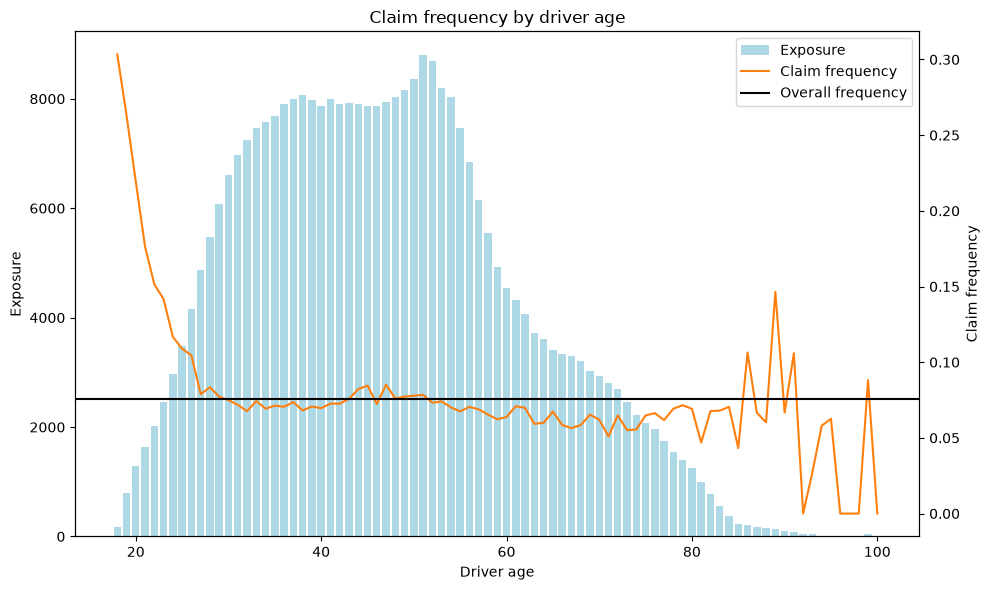

In [ ]:
from matplotlib import pyplot as plt

by_age = (
    df.groupby("DrivAge")
      .agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
)

by_age["claim_frequency"] = by_age["claims"] / by_age["exposure"]

overall_frequency = df["ClaimNb"].sum() / df["Exposure"].sum()

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(by_age.index, by_age["exposure"], color="lightblue", label="Exposure")
ax1.set_xlabel("Driver age")
ax1.set_ylabel("Exposure")

ax2 = ax1.twinx()
ax2.plot(by_age.index, by_age["claim_frequency"], color = "tab:orange", label = "Claim frequency")
ax2.axhline(overall_frequency, color="black", label = "Overall frequency")
ax2.set_ylabel("Claim frequency")
ax1.set_title("Claim frequency by driver age")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout()
plt.savefig("../figures/claim_frequency_by_driver_age.png", dpi = 150)
plt.show()

This plot shows the relationship between driver age and the frequency of claims, and shows that the frequency of claims decreses from 18 to about 25, and then stays roughly near the overall frequency from about 25 to 80, before the claim frequency gets erratic due to lower exposure.

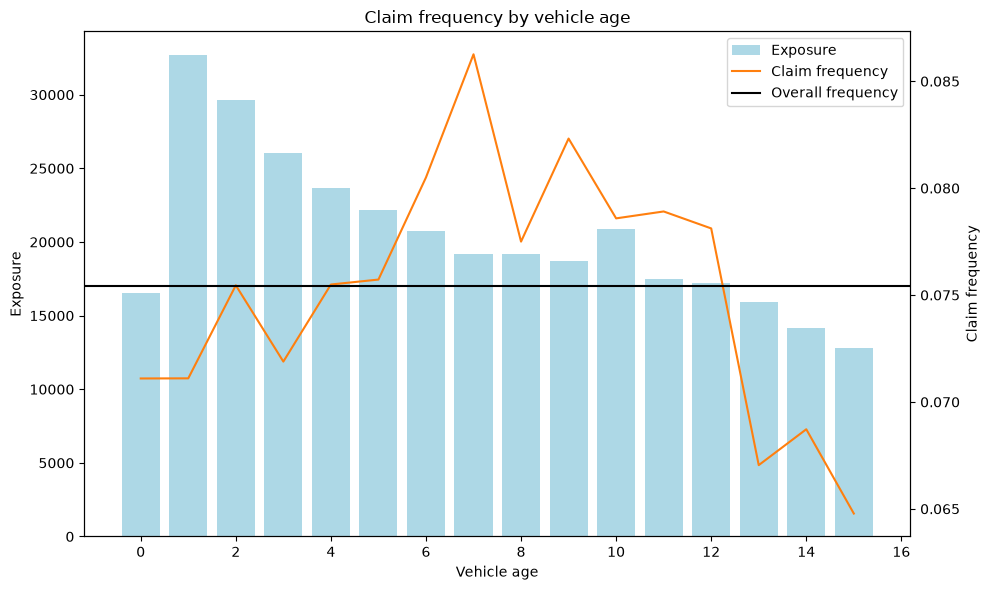

In [38]:
by_veh_age = (
    df.groupby("VehAge")
      .agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
)

by_veh_age["claim_frequency"] = by_veh_age["claims"] / by_veh_age["exposure"]

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(by_veh_age.index, by_veh_age["exposure"], color="lightblue", label="Exposure")
ax1.set_xlabel("Vehicle age")
ax1.set_ylabel("Exposure")

ax2 = ax1.twinx()
ax2.plot(by_veh_age.index, by_veh_age["claim_frequency"], color = "tab:orange", label = "Claim frequency")
ax2.axhline(overall_frequency, color="black", label = "Overall frequency")
ax2.set_ylabel("Claim frequency")
ax1.set_title("Claim frequency by vehicle age")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout()
plt.savefig("../figures/claim_frequency_by_vehicle_age.png", dpi = 150)
plt.show()

Lower claim frequency for younger (1-4) and older (13+) vehicles, and higher for vehicles between 7 and 9 years old

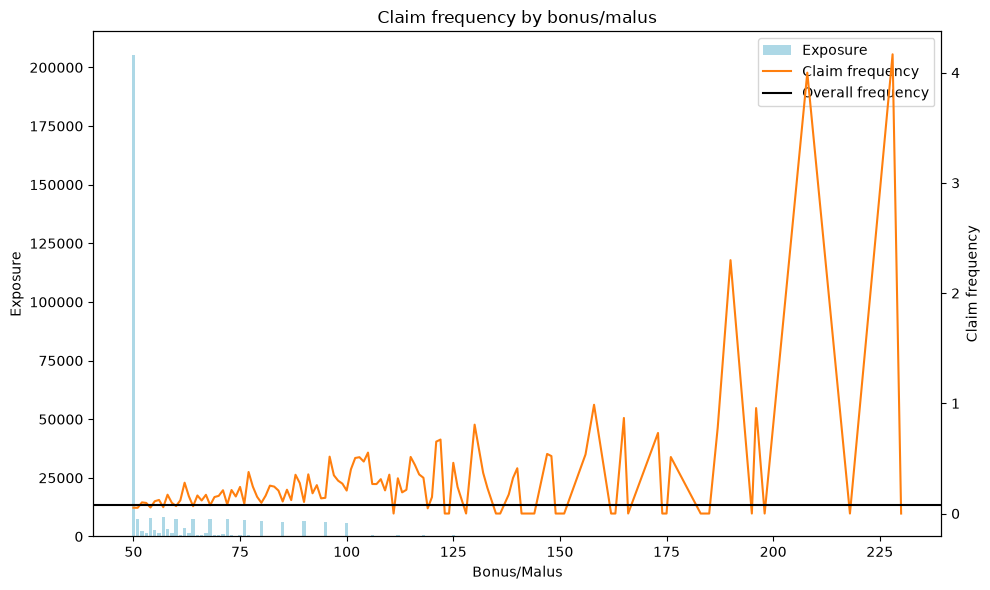

In [40]:
by_bonus_malus = (
    df.groupby("BonusMalus")
      .agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
)

by_bonus_malus["claim_frequency"] = by_bonus_malus["claims"] / by_bonus_malus["exposure"]

overall_frequency = df["ClaimNb"].sum() / df["Exposure"].sum()

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(by_bonus_malus.index, by_bonus_malus["exposure"], color="lightblue", label="Exposure")
ax1.set_xlabel("Bonus/Malus")
ax1.set_ylabel("Exposure")

ax2 = ax1.twinx()
ax2.plot(by_bonus_malus.index, by_bonus_malus["claim_frequency"], color = "tab:orange", label = "Claim frequency")
ax2.axhline(overall_frequency, color="black", label = "Overall frequency")
ax2.set_ylabel("Claim frequency")
ax1.set_title("Claim frequency by bonus/malus")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout()
plt.savefig("../figures/claim_frequency_by_bonus_malus.png", dpi = 150)
plt.show()

Claim frequency stays pretty close to the overall frequency, and at bonus-malus values above 100 the exposure is very low so its likely the shown frequencys arent accurate.

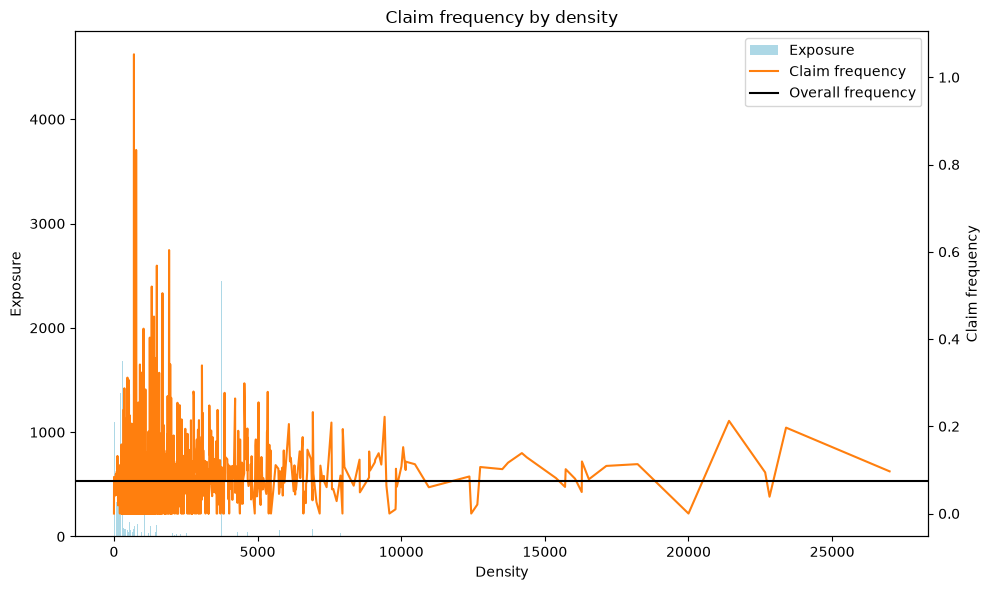

In [41]:
by_density = (
    df.groupby("Density")
      .agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
)

by_density["claim_frequency"] = by_density["claims"] / by_density["exposure"]

overall_frequency = df["ClaimNb"].sum() / df["Exposure"].sum()

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(by_density.index, by_density["exposure"], color="lightblue", label="Exposure")
ax1.set_xlabel("Density")
ax1.set_ylabel("Exposure")

ax2 = ax1.twinx()
ax2.plot(by_density.index, by_density["claim_frequency"], color = "tab:orange", label = "Claim frequency")
ax2.axhline(overall_frequency, color="black", label = "Overall frequency")
ax2.set_ylabel("Claim frequency")
ax1.set_title("Claim frequency by density")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout()
plt.savefig("../figures/claim_frequency_by_density.png", dpi = 150)
plt.show()

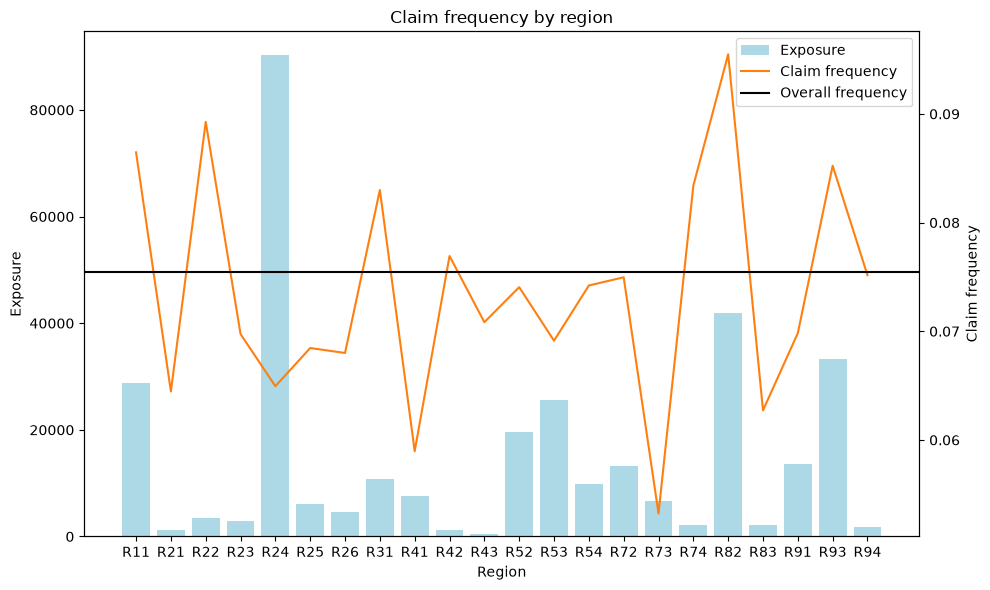

In [42]:
by_region = (
    df.groupby("Region")
      .agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
)

by_region["claim_frequency"] = by_region["claims"] / by_region["exposure"]

overall_frequency = df["ClaimNb"].sum() / df["Exposure"].sum()

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(by_region.index, by_region["exposure"], color="lightblue", label="Exposure")
ax1.set_xlabel("Region")
ax1.set_ylabel("Exposure")

ax2 = ax1.twinx()
ax2.plot(by_region.index, by_region["claim_frequency"], color = "tab:orange", label = "Claim frequency")
ax2.axhline(overall_frequency, color="black", label = "Overall frequency")
ax2.set_ylabel("Claim frequency")
ax1.set_title("Claim frequency by region")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout()
plt.savefig("../figures/claim_frequency_by_region.png", dpi = 150)
plt.show()